# Stage 3: Regression Modeling & Resale Confidence Evaluation

Evaluate simple OLS regression (`Price vs. Age` and `Price vs. Mileage`), joint Multiple Linear Regression, and the 100-tree Random Forest resale estimator with 80%/90% confidence intervals across all 4 cleaned CSV datasets.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.pipeline import (
    list_data_files,
    prepare_dataset,
    run_ols_regression,
    run_multiple_regression,
    train_resale_estimator,
    predict_with_confidence,
)

benchmark = []
for path in list_data_files():
    df, _, _ = prepare_dataset(path)
    age_reg = run_ols_regression(df, 'vehicle_age')
    km_reg = run_ols_regression(df, 'km_10k')
    _, mv_r2, mv_mae = run_multiple_regression(df)
    rf_bundle = train_resale_estimator(df)
    benchmark.append({
        'Dataset': path.name,
        'Clean Rows': len(df),
        'Age OLS Slope (L/yr)': round(age_reg['slope'], 3),
        'Age R2': round(age_reg['r2'], 3),
        'Mileage Slope (L/10k)': round(km_reg['slope'], 3),
        'Mileage R2': round(km_reg['r2'], 3),
        'Multiple Reg R2': round(mv_r2, 3),
        'RF Test R2': round(rf_bundle['test_r2'], 3),
        'RF Test MAE (L)': round(rf_bundle['test_mae'], 2),
    })
print(pd.DataFrame(benchmark).to_string(index=False))

                       Dataset  Clean Rows  Age OLS Slope (L/yr)  Age R2  Mileage Slope (L/10k)  Mileage R2  Multiple Reg R2  RF Test R2  RF Test MAE (L)
            Car details v3.csv        6908                -0.480   0.343                 -0.175       0.055            0.618       0.913             0.72
            car details v4.csv        2054                -1.939   0.153                 -1.506       0.074            0.673       0.673             3.75
CAR DETAILS FROM CAR DEKHO.csv        3577                -0.457   0.330                 -0.203       0.063            0.432       0.600             1.59
                  car data.csv         299                -0.365   0.066                  0.239       0.020            0.432       0.730             1.49


In [2]:
v3_df, _, _ = prepare_dataset(ROOT / 'data' / 'Car details v3.csv')
coef_df, mv_r2, mv_mae = run_multiple_regression(v3_df)
print(f'Multiple Regression (Car details v3.csv): R2={mv_r2:.3f}, MAE=Rs.{mv_mae:.2f}L')
print(coef_df.round(4).to_string(index=False))

Multiple Regression (Car details v3.csv): R2=0.618, MAE=Rs.1.72L
              Feature  Price Impact (Lakhs)
  Vehicle Age (+1 yr)               -0.3156
Odometer (+10,000 km)               -0.0720
       Engine (+1 cc)                0.0007
       Power (+1 bhp)                0.0880
    Mileage (+1 kmpl)                0.0647
     Owner Count (+1)               -0.3735
    fuel: type_Diesel                0.4078
       fuel: type_Lpg                1.3037
    fuel: type_Petrol               -0.1975
 transmission: Manual               -3.2914


Estimate: Rs.5.67 L | 80% CI: [5.09, 6.15] | 90% CI: [4.78, 6.23]


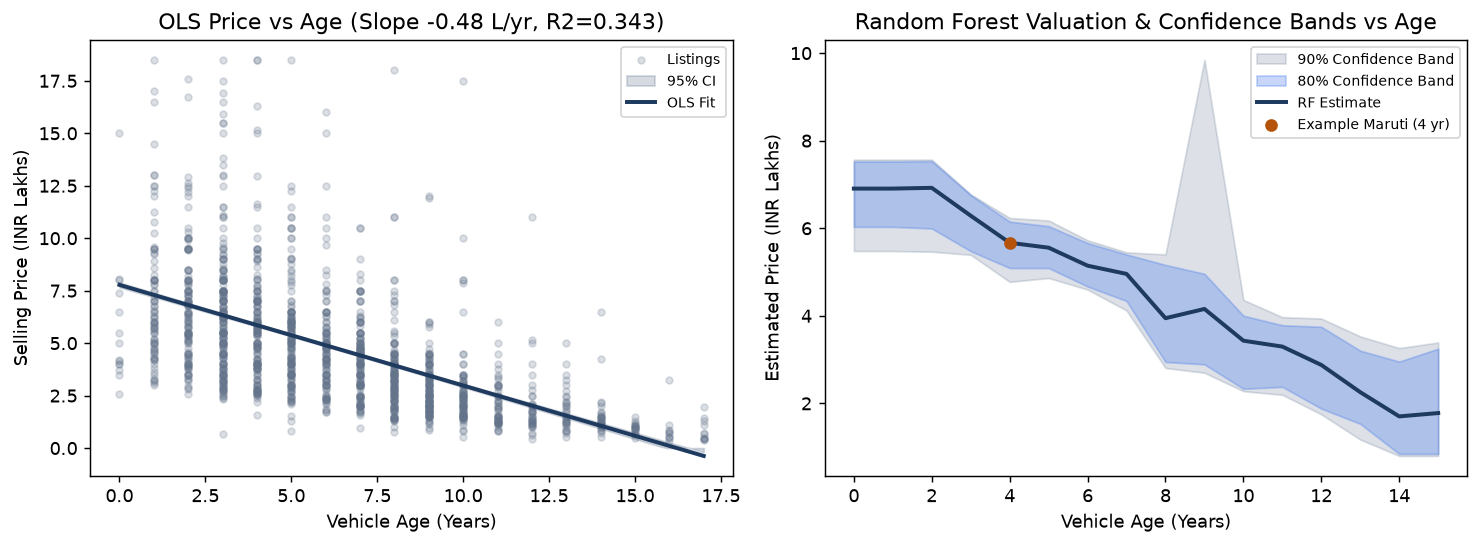

In [3]:
v3_bundle = train_resale_estimator(v3_df)
sample_car = {
    'brand': 'Maruti',
    'vehicle_age': 4.0,
    'km_driven': 45000.0,
    'fuel_type': 'Diesel',
    'transmission': 'Manual',
    'owner_num': 1.0,
    'engine_cc': 1248.0,
    'power_bhp': 74.0,
    'mileage_kmpl': 23.4,
    'torque_nm': 190.0,
    'seats': 5.0,
}
res = predict_with_confidence(v3_bundle, sample_car)
print(f"Estimate: Rs.{res['estimate_lakh']:.2f} L | 80% CI: [{res['lo80']:.2f}, {res['hi80']:.2f}] | 90% CI: [{res['lo90']:.2f}, {res['hi90']:.2f}]")

age_reg = run_ols_regression(v3_df, 'vehicle_age')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

smp = age_reg['sample']
curve = age_reg['curve']
axes[0].scatter(smp['vehicle_age'], smp['price_lakh'], alpha=0.22, s=14, color='#64748B', label='Listings')
axes[0].fill_between(curve['x'], curve['ci_low'], curve['ci_high'], alpha=0.18, color='#1E3A5F', label='95% CI')
axes[0].plot(curve['x'], curve['fit'], color='#1E3A5F', lw=2.2, label='OLS Fit')
axes[0].set_title(f"OLS Price vs Age (Slope {age_reg['slope']:+.2f} L/yr, R2={age_reg['r2']:.3f})")
axes[0].set_xlabel('Vehicle Age (Years)')
axes[0].set_ylabel('Selling Price (INR Lakhs)')
axes[0].legend(fontsize=8)

ac = res['age_curve']
axes[1].fill_between(ac['age'], ac['p05'], ac['p95'], alpha=0.15, color='#1E3A5F', label='90% Confidence Band')
axes[1].fill_between(ac['age'], ac['p10'], ac['p90'], alpha=0.25, color='#2563EB', label='80% Confidence Band')
axes[1].plot(ac['age'], ac['est'], color='#1E3A5F', lw=2.2, label='RF Estimate')
axes[1].scatter([sample_car['vehicle_age']], [res['estimate_lakh']], color='#B45309', zorder=5, label='Example Maruti (4 yr)')
axes[1].set_title('Random Forest Valuation & Confidence Bands vs Age')
axes[1].set_xlabel('Vehicle Age (Years)')
axes[1].set_ylabel('Estimated Price (INR Lakhs)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()